Today's topics:
* scoring a fit with RMSE
* comparing model forms with residual plots
* checking a form against a known point

# Choosing a model for a printed part

Last time we minimized a sum of squared residuals over two parameters.

Today we will choose between three model forms for one compression test.
We will score each form with the same number.

*Which form should we use, and how do we decide?*

Today's data come from our lab (Oturak et al. 2026, [3D Printing and Additive Manufacturing](https://doi.org/10.1089/3dp.2024.0033)).
It is the same compression test we fit in Lectures 19 to 22.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/4f/Compression_test-Universal_testing_machine.jpg/960px-Compression_test-Universal_testing_machine.jpg" alt="A cylindrical specimen sitting between the two flat steel platens of a universal testing machine, with the load cell above and a control panel to the side" width=360/>

*Photo by Cjp24, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Compression_test-Universal_testing_machine.jpg).*

Above: A composite cylinder between the platens of an [Instron universal testing machine](https://en.wikipedia.org/wiki/Universal_testing_machine).

The upper platen moves down while a load cell records the force.
Our part was printed by [fused deposition modeling](https://en.wikipedia.org/wiki/Fused_filament_fabrication) from two thermoplastics.

Cellular solids often show three regions like these.
The printed-part curve has similar regions, but the dataset doesn't record the part's internal architecture.

Let's load the data, flip the compression signs, and zero the first reading:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

# read the compression test from our course repository:
compression = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/compression_test.csv')

position = -compression['Position(Linear:Position) (in)'].to_numpy()  # in, flipped so compression is positive
force = -compression['Force(Linear:Load) (lb)'].to_numpy()            # lb, flipped the same way
position = position - position[0]  # zero the first reading
force = force - force[0]
print(len(position), 'readings')

374 readings


Let's plot the raw readings:

Text(0, 0.5, 'force (lb)')

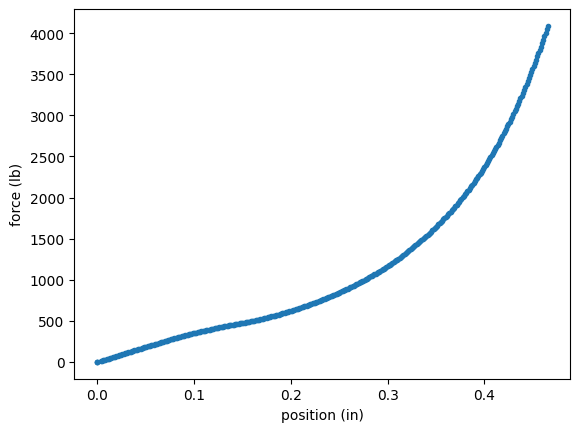

In [2]:
fig, ax = plt.subplots()
ax.plot(position, force, '.')
ax.set_xlabel('position (in)')
ax.set_ylabel('force (lb)')

The force rises, flattens a little near 0.15 in, and then climbs steeply.

# Scoring a fit

We will compare every fitted curve with the same score.

Let's write the RMSE as a function, so each model gets it the same way.
It comes out in lb, the units of `force`:

In [3]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    residuals = y - y_fit  # miss at each reading
    return np.sqrt(np.mean(residuals**2))

# Comparing model forms

## A straight line

We start with the simplest form.
Let's fit a line with `linregress`:

In [4]:
line = stats.linregress(position, force)
force_line = line.slope * position + line.intercept
print(f'slope = {line.slope:.0f} lb/in, intercept = {line.intercept:.0f} lb')
print(f'RMSE = {rmse(force, force_line):.0f} lb')

slope = 6891 lb/in, intercept = -471 lb
RMSE = 395 lb


The slope is a stiffness.

> The machine frame and platens deflect a little too.
> So it is an effective stiffness of the part and the test system together.

## An exponential

Now let's fit $F = a\,(e^{bx} - 1)$ from Lecture 19.
This form can follow the steep rise at the end.

`popt` follows the parameter order in `exp_model`:

In [5]:
def exp_model(x, a, b):
    """Force in lb from F = a * (exp(b * x) - 1).

    x:  position in in (a number or an array)
    a:  force scale in lb
    b:  growth rate in 1/in
    """
    return a * (np.exp(b * x) - 1)

popt_exp, pcov_exp = optimize.curve_fit(exp_model, position, force)  # popt_exp holds a, b in that order
force_exp = exp_model(position, *popt_exp)                           # * unpacks a and b into the call
print(f'a = {popt_exp[0]:.0f} lb, b = {popt_exp[1]:.2f} 1/in')
print(f'RMSE = {rmse(force, force_exp):.0f} lb')                     # about 99 lb, a quarter of the line's

a = 215 lb, b = 6.31 1/in
RMSE = 99 lb


Let's plot both curves on the data:

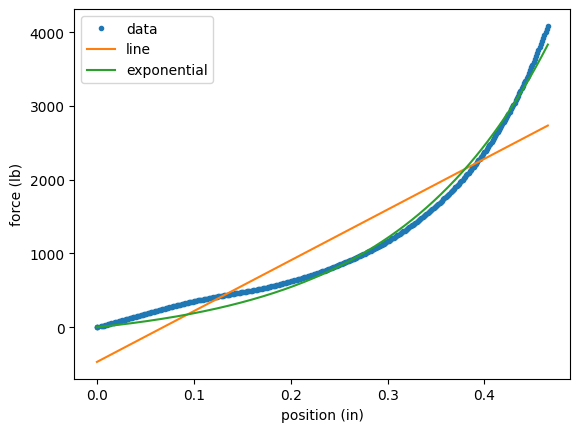

In [6]:
fig, ax = plt.subplots()
ax.plot(position, force, '.', label='data')
ax.plot(position, force_line, '-', label='line')
ax.plot(position, force_exp, '-', label='exponential')
ax.set_xlabel('position (in)')
ax.set_ylabel('force (lb)')
ax.legend()

The exponential follows the bend at both ends.
The line misses it.

## A quadratic

A quadratic, $F = a x^2 + b x + c$, adds curvature to a line.
Let's fit it the same way:

In [7]:
def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

popt_quad, pcov_quad = optimize.curve_fit(quadratic, position, force)
force_quad = quadratic(position, *popt_quad)
print(f'RMSE = {rmse(force, force_quad):.0f} lb')

RMSE = 161 lb


## Comparing residuals

An RMSE is one number for the whole curve.
The residuals show the miss at each position along the test.

Let's plot the residuals of the line and the exponential on one axis:

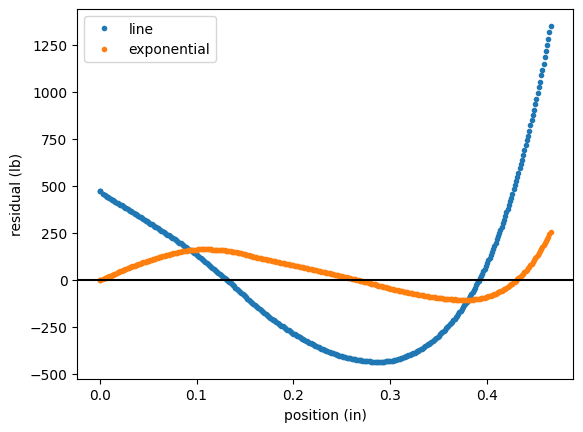

In [8]:
fig, ax = plt.subplots()
ax.plot(position, force - force_line, '.', label='line')
ax.plot(position, force - force_exp, '.', label='exponential')
ax.axhline(0, color='black')                                    # zero residual
ax.set_xlabel('position (in)')
ax.set_ylabel('residual (lb)')
ax.legend()

The line's residuals are positive at both ends and negative in the middle.
The exponential residuals have the same broad pattern at a smaller magnitude.

Which curve would we trust more?

# Checking a form against a known point

We subtracted the first reading, so the curve starts at zero force and zero displacement.
A model for this curve should pass through that point.

Let's evaluate each model at zero displacement:

In [9]:
print(f'line:        {line.intercept:.0f} lb')                # the intercept is the force at x = 0
print(f'quadratic:   {quadratic(0, *popt_quad):.0f} lb')
print(f'exponential: {exp_model(0, *popt_exp):.0f} lb')       # exactly 0, since exp(0) - 1 = 0

line:        -471 lb
quadratic:   329 lb
exponential: 0 lb


The line predicts a negative force at zero displacement.
The quadratic predicts a positive one.

The exponential passes through zero because of its form, $e^0 - 1 = 0$.
That's a third check beside RMSE and the residual pattern.

### [Check your understanding]

Let's go back to the titanium alloys (Salvador et al. 2022).
We want to predict ultimate tensile strength from yield strength.

1. Select the data.
   - Keep only the rows where `test_mode` is `'tension'` and both `YS_MPa` and `UTS_MPa` are present.
   - Store the two columns as arrays `x` and `y`.
   - Print how many alloys you have.
     You should get 166.
2. Compare two forms.
   - Fit a line and `quadratic` to `y` against `x`.
   - Print `rmse` for each.
     You should get about 119.0 MPa and 117.7 MPa.

*Which form would you report, and what would you check before deciding?*

**Optional challenge:**
- Plot the residuals of both fits against `x`.
- Does either one show a pattern?

In [10]:
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/biomaterials_ti_alloys.csv')

## Three questions

Let's answer these out loud, with the cells above on the screen.

1. What does `optimize.curve_fit(exp_model, position, force)` do with `exp_model`, and what comes back?
2. Would we trust the exponential at 0.6 in, past the end of our data?
3. Which tool would we use for a line, for a model function, and for an objective we write ourselves?

# Summary

* One function, `rmse(y, y_fit)`, gives every model the same score in the units of the data.
* `linregress` fits a line.
* `curve_fit` fits a model function.
* `minimize` minimizes a scalar objective we write.
* A residual plot shows where along the test a model misses.
* The slope of the line is an effective stiffness of the part and the test system.
* Our curve starts at zero force and zero displacement, so a model for it should pass through that point.

The answer to our question about the printed part: among these three forms we'd choose the exponential.

It has the lowest RMSE and the smallest residual pattern.
It also passes through our zero point.

## Further reading

* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [16.5 "Least Square Regression for Nonlinear Functions"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.05-Least-Square-Regression-for-Nonlinear-Functions.html), which fits several nonlinear forms to data
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* [`scipy.optimize.curve_fit` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html)
* The compression data: Oturak, McKeehan, Zawaski, and Reinhart, "Data-Driven Design Space Analysis for Multimaterial Thermoplastic Composites Manufactured by Fused Filament Fabrication," *3D Printing and Additive Manufacturing* 13 (2026) 39-49, [DOI 10.1089/3dp.2024.0033](https://doi.org/10.1089/3dp.2024.0033)
* The titanium alloy data: Salvador, C. A. F. et al. "A compilation of experimental data on the mechanical properties and microstructural features of Ti-alloys." *Scientific Data* 9, 188 (2022). [DOI 10.1038/s41597-022-01283-9](https://doi.org/10.1038/s41597-022-01283-9), CC BY 4.0
* Photo credit: compression test, Cjp24, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Compression_test-Universal_testing_machine.jpg)

# Appendix A: A line over a shorter range

Optional.

The slope depends on how much of the test we fit.
Let's fit a line to the first 0.1 in only, with a mask on `position`:

In [11]:
early = position < 0.1  # True for readings in the first 0.1 in
line_early = stats.linregress(position[early], force[early])
print(f'slope over the first 0.1 in = {line_early.slope:.0f} lb/in')
print(f'slope over the whole test   = {line.slope:.0f} lb/in')

slope over the first 0.1 in = 3576 lb/in
slope over the whole test   = 6891 lb/in


The stiffness we report depends on the range we fit.
We state the range with the number.